# 06 — Fidelity and information

The Banchi-Braunstein-Pirandola fidelity for arbitrary multimode Gaussian
states, Bures distance, entropies, mutual information, and the
Williamson/Bloch-Messiah decompositions this all builds on.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvcircuit as cv
from cvcircuit import decompositions

np.set_printoptions(precision=4, suppress=True)

## Fidelity

`fidelity()` returns the **squared** overlap (matching `qcircsim`'s
convention): for two coherent states, `fidelity(coherent(a), coherent(b))
== exp(-abs(a - b)**2)` exactly.

In [2]:
a, b = 0.5 + 0.3j, -0.2 - 0.1j
print("fidelity:", cv.fidelity(cv.coherent(a), cv.coherent(b)))
print("exp(-|a-b|^2):", np.exp(-abs(a - b) ** 2))

fidelity: 0.522045776761016
exp(-|a-b|^2): 0.522045776761016


It works for arbitrary multimode Gaussian states, not just simple special
cases -- e.g. fidelity between two independently-prepared random states:

In [3]:
s1 = cv.random_state(3, seed=1)
s2 = cv.random_state(3, seed=2)
print("fidelity:", cv.fidelity(s1, s2))
print("fidelity(s, s):", cv.fidelity(s1, s1), "(always 1, up to floating-point error)")

fidelity: 0.2224237011428562
fidelity(s, s): 1.0 (always 1, up to floating-point error)


### Fidelity as a function of loss

A useful sanity plot: how a squeezed state's fidelity with its lossless
self degrades with transmission.

Text(0, 0.5, 'fidelity with the lossless state')

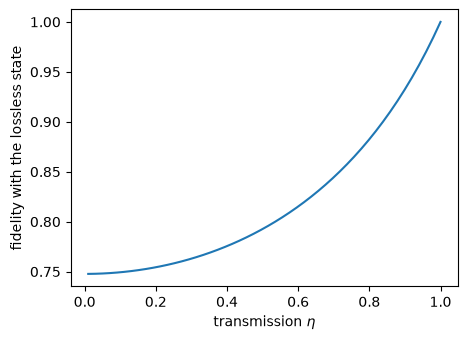

In [4]:
ideal = cv.squeezed(0.8)
etas = np.linspace(0.01, 1.0, 50)
fidelities = [cv.fidelity(ideal, ideal.loss(eta, mode=0)) for eta in etas]

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.plot(etas, fidelities)
ax.set_xlabel("transmission $\\eta$")
ax.set_ylabel("fidelity with the lossless state")

## Bures distance and trace-distance bounds

In [5]:
print("Bures distance:", cv.bures_distance(s1, s2))
print("Bures angle:", cv.bures_angle(s1, s2))
lower, upper = cv.trace_distance_bounds(s1, s2)
print(f"Fuchs-van de Graaf trace-distance bounds: [{lower:.4f}, {upper:.4f}]")

Bures distance: 1.0279901039977524
Bures angle: 1.0796713739352
Fuchs-van de Graaf trace-distance bounds: [0.5284, 0.8818]


## Entropies and mutual information

Von Neumann and Renyi entropies are closed forms in the symplectic
eigenvalues (shot-noise units); the Renyi-2 entropy is always
`-log2(purity)`.

In [6]:
s = cv.random_state(2, seed=3)
print("purity:", s.purity())
print("von Neumann entropy:", s.von_neumann_entropy(), "bits")
print("Renyi-2 entropy:", s.renyi_entropy(alpha=2), " -log2(purity):", -np.log2(s.purity()))
print("mutual information I(mode0:mode1):", cv.mutual_information(s, [0]), "bits")

purity: 0.2607445807002139
von Neumann entropy: 2.656801913600872 bits
Renyi-2 entropy: 1.939290826718254  -log2(purity): 1.9392908267182543
mutual information I(mode0:mode1): 2.4018759075603926 bits


## Williamson decomposition

Every covariance matrix factors as `S @ D @ S.T`, `S` symplectic, `D`
diagonal (the symplectic eigenvalues) -- the Gaussian-state analogue of
diagonalizing a density matrix.

In [7]:
s_mat, d_mat = s.williamson()
print("D (symplectic eigenvalues, repeated pairwise):", np.diag(d_mat))
print("reconstruction error:", np.max(np.abs(s_mat @ d_mat @ s_mat.T - s.cov)))

D (symplectic eigenvalues, repeated pairwise): [1.4736 1.4736 2.6025 2.6025]
reconstruction error: 7.105427357601002e-15


## Bloch-Messiah decomposition

Any symplectic transformation factors as `O1 @ Z @ O2`: an interferometer,
independent single-mode squeezers, another interferometer -- the normal
form behind "any Gaussian unitary can be built from beamsplitters and
single-mode squeezers".

In [8]:
from cvcircuit import ops

S_random = ops.random_symplectic(3, seed=4)
O1, Z, O2 = decompositions.bloch_messiah(S_random)
squeezing_factors = np.diag(Z)
print("squeezing factors:", squeezing_factors)
print("reciprocal pairs (should multiply to 1):", squeezing_factors[0::2] * squeezing_factors[1::2])
print("reconstruction error:", np.max(np.abs(O1 @ Z @ O2 - S_random)))

squeezing factors: [2.6545 0.3767 1.6675 0.5997 1.0842 0.9223]
reciprocal pairs (should multiply to 1): [1. 1. 1.]
reconstruction error: 3.552713678800501e-15
